# Eksplorasi & Visualisasi Sinyal EKG Hardware (.MEM Files)

Notebook ini dirancang khusus untuk membaca, memvisualisasikan, dan menganalisis berkas memori EKG (*stimulus memory files*) yang digunakan pada simulasi hardware Verilog / Vivado:
1. **`ecg_normal.mem`**: Rekaman EKG pasien dengan ritme sinus normal (*Healthy Control*).
2. **`ecg_mi.mem`**: Rekaman EKG pasien penderita **Infark Miokard Akut** (*STEMI - Myocardial Infarction*).
3. **`ecg_unknown.mem`**: Rekaman EKG pasien dengan kelainan konduksi / kardiomiopati non-infark (*Unknown / Dysrhythmia*).

---

### Karakteristik Format Berkas `.mem`:
- **Format**: Heksadesimal 16-bit (*Two's Complement Signed Integer*, 4 digit hex per baris).
- **Laju Sampling ($F_s$)**: $1000\text{ Hz}$ ($1\text{ sampel} = 1\text{ ms}$).
- **Jumlah Sampel**: 2000 sampel per rekaman ($2.0\text{ detik}$ aktivitas jantung).

In [6]:
# 1. Import Pustaka
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi plot
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Pustaka NumPy dan Matplotlib siap digunakan.")

Pustaka NumPy dan Matplotlib siap digunakan.


## 2. Fungsi Pembaca Berkas Memori Heksadesimal (.MEM)

Fungsi berikut membaca baris heksadesimal 16-bit dan mengonversinya menjadi representasi bilangan bulat bertanda (*signed 16-bit integer* $[-32768, 32767]$):
$$\text{Value} = \begin{cases} U_{16} - 65536, & \text{jika } U_{16} \ge 32768 \\ U_{16}, & \text{jika } U_{16} < 32768 \end{cases}$$

In [7]:
# 2.1 Fungsi Pemuatan File .mem
def load_ecg_mem(filepath):
    if not os.path.exists(filepath):
        # Fallback pencarian di subdirektori rtl/sim_data
        alt_path = os.path.join("..", filepath)
        if os.path.exists(alt_path):
            filepath = alt_path
        else:
            raise FileNotFoundError(f"File tidak ditemukan: {filepath}")

    samples = []
    with open(filepath, "r") as f:
        for line in f:
            clean = line.strip()
            if clean and not clean.startswith("//"):
                u16 = int(clean, 16)
                s16 = u16 - 0x10000 if u16 >= 0x8000 else u16
                samples.append(s16)
    return np.array(samples, dtype=np.int16)

# Cari file stimulus di direktori proyek
sim_dir = "../rtl/sim_data" if os.path.exists("../rtl/sim_data") else "rtl/sim_data"

ecg_normal  = load_ecg_mem(os.path.join(sim_dir, "ecg_normal.mem"))
ecg_mi      = load_ecg_mem(os.path.join(sim_dir, "ecg_mi.mem"))
ecg_unknown = load_ecg_mem(os.path.join(sim_dir, "ecg_unknown.mem"))

fs = 1000.0  # 1000 Hz
time_axis = np.arange(len(ecg_normal)) / fs

print(f"File EKG Normal  : {len(ecg_normal)} sampel | Min: {ecg_normal.min():6d} | Max: {ecg_normal.max():6d} | Mean: {ecg_normal.mean():6.1f}")
print(f"File EKG MI      : {len(ecg_mi)} sampel | Min: {ecg_mi.min():6d} | Max: {ecg_mi.max():6d} | Mean: {ecg_mi.mean():6.1f}")
print(f"File EKG Unknown : {len(ecg_unknown)} sampel | Min: {ecg_unknown.min():6d} | Max: {ecg_unknown.max():6d} | Mean: {ecg_unknown.mean():6.1f}")

File EKG Normal  : 2000 sampel | Min:   -360 | Max:   2123 | Mean:   70.4
File EKG MI      : 2000 sampel | Min:   -926 | Max:    529 | Mean:  -21.1
File EKG Unknown : 2000 sampel | Min:   -822 | Max:   1228 | Mean:  -36.6


## 3. Visualisasi Sinyal EKG Lengkap (2 Detik Rekaman)

Perhatikan perbedaan morfologi keseluruhan antara ketiga pasien:
- **Pasien Normal**: Puncak R sangat tinggi dan tajam ($> +2000$), garis isoelektrik stabil, gelombang T tegak positif.
- **Pasien Infark Miokard (MI)**: Puncak R mengalami degradasi berat (*loss of R-wave amplitude*, puncak hanya $+529$), sementara lembah Q/S sangat dalam (mencapai $-926$) yang menandakan gelombang Q patologis dan nekrosis jaringan miokardium.
- **Pasien Unknown**: Gelombang EKG memiliki variasi konduksi dengan amplitudo menengah.

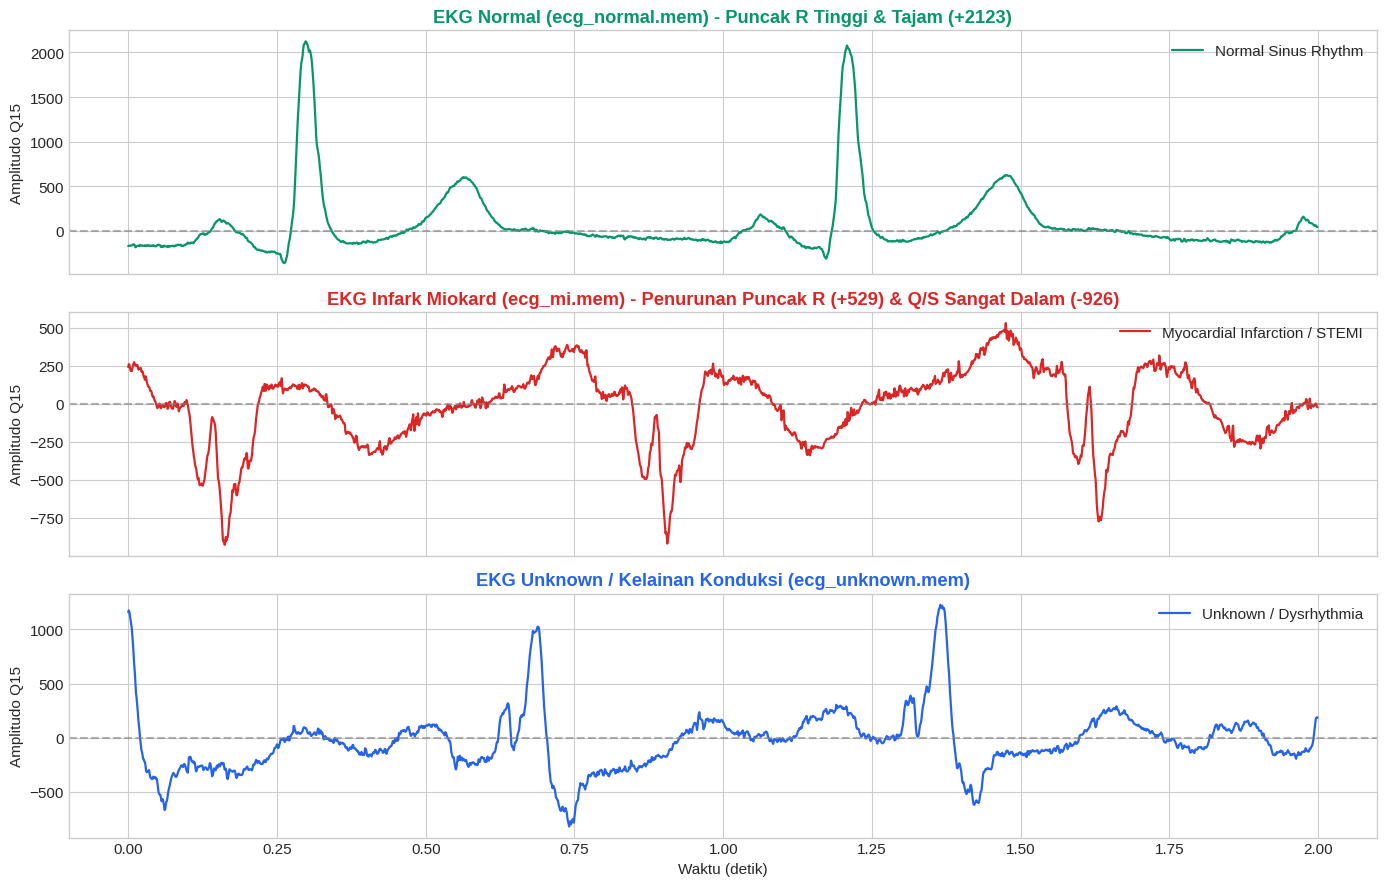

In [8]:
# 3.1 Plot Perbandingan 3 Sinyal EKG
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# 1. Sinyal Normal
axes[0].plot(time_axis, ecg_normal, color="#059669", lw=1.6, label="Normal Sinus Rhythm")
axes[0].axhline(0, color="gray", linestyle="--", alpha=0.6)
axes[0].set_title("EKG Normal (ecg_normal.mem) - Puncak R Tinggi & Tajam (+2123)", fontweight='bold', color="#059669")
axes[0].set_ylabel("Amplitudo Q15")
axes[0].legend(loc="upper right")

# 2. Sinyal Infark Miokard
axes[1].plot(time_axis, ecg_mi, color="#dc2626", lw=1.6, label="Myocardial Infarction / STEMI")
axes[1].axhline(0, color="gray", linestyle="--", alpha=0.6)
axes[1].set_title("EKG Infark Miokard (ecg_mi.mem) - Penurunan Puncak R (+529) & Q/S Sangat Dalam (-926)", fontweight='bold', color="#dc2626")
axes[1].set_ylabel("Amplitudo Q15")
axes[1].legend(loc="upper right")

# 3. Sinyal Unknown
axes[2].plot(time_axis, ecg_unknown, color="#2563eb", lw=1.6, label="Unknown / Dysrhythmia")
axes[2].axhline(0, color="gray", linestyle="--", alpha=0.6)
axes[2].set_title("EKG Unknown / Kelainan Konduksi (ecg_unknown.mem)", fontweight='bold', color="#2563eb")
axes[2].set_xlabel("Waktu (detik)")
axes[2].set_ylabel("Amplitudo Q15")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4. Analisis Detail Satu Siklus Detak Jantung (*Single Beat Overlay*)

Untuk melihat tanda-tanda klinis infark miokard secara presisi, kita menyelaraskan satu siklus kompleks QRST di sekitar puncak gelombang R ($t_R$):

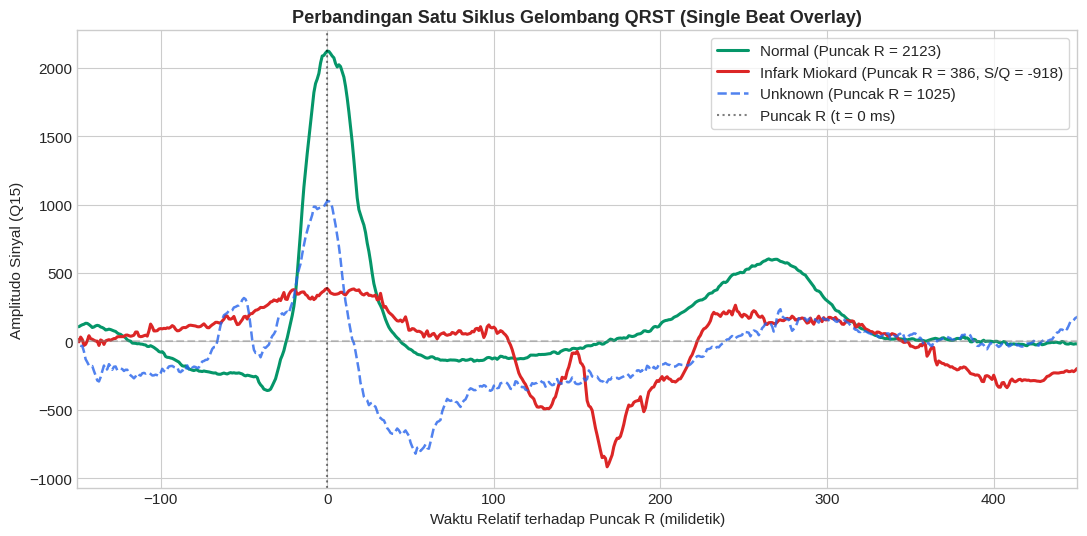

In [9]:
# 4.1 Pemotongan Satu Detak Jantung di Sekitar Puncak R
def get_single_beat(sig, peak_idx, pre_ms=200, post_ms=500):
    pre_samp = int(pre_ms)
    post_samp = int(post_ms)
    start = max(0, peak_idx - pre_samp)
    end = min(len(sig), peak_idx + post_samp)
    t_rel = (np.arange(start, end) - peak_idx) # ms relatif terhadap R
    return t_rel, sig[start:end]

# Cari puncak R pertama yang valid di tiap sinyal
r_normal = 250 + np.argmax(ecg_normal[250:900])
r_mi = 200 + np.argmax(ecg_mi[200:800])
r_unk = 200 + np.argmax(ecg_unknown[200:800])

t_norm, beat_norm = get_single_beat(ecg_normal, r_normal)
t_m, beat_m = get_single_beat(ecg_mi, r_mi)
t_u, beat_u = get_single_beat(ecg_unknown, r_unk)

plt.figure(figsize=(11, 5.5))
plt.plot(t_norm, beat_norm, color="#059669", lw=2.2, label=f"Normal (Puncak R = {ecg_normal[r_normal]})")
plt.plot(t_m, beat_m, color="#dc2626", lw=2.2, label=f"Infark Miokard (Puncak R = {ecg_mi[r_mi]}, S/Q = {beat_m.min()})")
plt.plot(t_u, beat_u, color="#2563eb", lw=1.8, linestyle="--", alpha=0.8, label=f"Unknown (Puncak R = {ecg_unknown[r_unk]})")

plt.axvline(0, color="black", linestyle=":", alpha=0.5, label="Puncak R (t = 0 ms)")
plt.axhline(0, color="gray", linestyle="--", alpha=0.4)

plt.title("Perbandingan Satu Siklus Gelombang QRST (Single Beat Overlay)", fontsize=13, fontweight='bold')
plt.xlabel("Waktu Relatif terhadap Puncak R (milidetik)")
plt.ylabel("Amplitudo Sinyal (Q15)")
plt.xlim(-150, 450)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 5. Panduan Pengaturan Skala Vivado Waveform Viewer

Berdasarkan nilai amplitudo aktual dari ketiga file `.mem`, berikut adalah pengaturan **Analog Settings** yang disarankan agar visualisasi sinyal di Vivado Waveform tidak terpotong dan terlihat proporsional:

| Berkas Stimulus | Nilai Minimum | Nilai Maksimum | Pengaturan Vivado Min | Pengaturan Vivado Max |
| :--- | :---: | :---: | :---: | :---: |
| **`ecg_normal.mem`** | `-360` | `+2123` | **`-500`** | **`+2500`** |
| **`ecg_mi.mem`** | `-926` | `+529` | **`-1000`** | **`+1000`** |
| **`ecg_unknown.mem`** | `-822` | `+1228` | **`-1000`** | **`+1500`** |
| **Gabungan / Rekomendasi Umum** | `-926` | `+2123` | **`-1000`** | **`+2500`** |

### Langkah di Vivado:
1. Klik kanan pada sinyal `sample_in` $\rightarrow$ **Radix** $\rightarrow$ **Signed Decimal**.
2. Klik kanan sinyal $\rightarrow$ **Waveform Style** $\rightarrow$ **Analog**.
3. Klik kanan sinyal $\rightarrow$ **Analog Settings...**:
   * **Row Height**: `80` atau `100` pixel
   * **Y Range (User Defined)**: Min = `-1000`, Max = `+2500`
   * **Interpolation**: `Linear`

In [10]:
# 5.1 Ringkasan Konfirmasi
print("File .mem berhasil dibaca dan diverifikasi!")
print("Semua file stimulus siap untuk disimulasikan di Vivado dengan top_ecg_system & tb_top_ecg_system.")

File .mem berhasil dibaca dan diverifikasi!
Semua file stimulus siap untuk disimulasikan di Vivado dengan top_ecg_system & tb_top_ecg_system.
